# ISIC

## Imports and Loading

In [14]:
import os
from pathlib import Path
import random
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image

try:
    import cv2
except Exception:
    cv2 = None

try:
    import imagehash
except Exception:
    imagehash = None




In [2]:
PROJECT_DIR = Path("/Users/matteozabban/Desktop/CityU/EE4016/Project")

TRAIN_IMG_DIR = PROJECT_DIR / "ISIC_2019_Training_Input"
TEST_IMG_DIR  = PROJECT_DIR / "ISIC_2019_Test_Input"

TRAIN_GT_PATH   = PROJECT_DIR / "ISIC_2019_Training_GroundTruth.csv"
TRAIN_META_PATH = PROJECT_DIR / "ISIC_2019_Training_Metadata.csv"
TEST_META_PATH  = PROJECT_DIR / "ISIC_2019_Test_Metadata.csv"
TEST_GT_PATH    = PROJECT_DIR / "ISIC_2019_Test_GroundTruth.csv"   

train_gt = pd.read_csv(TRAIN_GT_PATH)
train_meta = pd.read_csv(TRAIN_META_PATH)
test_meta = pd.read_csv(TEST_META_PATH)

print("train_gt:", train_gt.shape)
print("train_meta:", train_meta.shape)
print("test_meta:", test_meta.shape)

print("train_gt cols:", train_gt.columns.tolist())
print("train_meta cols:", train_meta.columns.tolist())
print("test_meta cols:", test_meta.columns.tolist())

train_gt.head()

train_gt: (25331, 10)
train_meta: (25331, 5)
test_meta: (8238, 4)
train_gt cols: ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']
train_meta cols: ['image', 'age_approx', 'anatom_site_general', 'lesion_id', 'sex']
test_meta cols: ['image', 'age_approx', 'anatom_site_general', 'sex']


,image,MEL,NV,BCC,AK,BKL,DF,VASC,SCC,UNK
0,ISIC_0000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0000001,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0000002,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0000003,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0000004,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Data Cleaning and Preprocessing

In [3]:
def resolve_image_path(img_dir: Path, image_id: str):
    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        p = img_dir / f"{image_id}{ext}"
        if p.exists():
            return p
    matches = list(img_dir.rglob(f"{image_id}.*"))
    if matches:
        return matches[0]
    for p in img_dir.rglob("*"):
        if p.is_file() and p.stem.startswith(image_id):
            return p
    return None

def list_image_stems(img_dir: Path):
    exts = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}
    return {p.stem for p in img_dir.rglob("*") if p.is_file() and p.suffix in exts}

train_stems = list_image_stems(TRAIN_IMG_DIR)
test_stems = list_image_stems(TEST_IMG_DIR)

print("Train images on disk:", len(train_stems))
print("Test images on disk :", len(test_stems))

missing_train = set(train_gt["image"]) - train_stems
print("Missing train images referenced by GT:", len(missing_train))
print("Examples:", list(sorted(missing_train))[:10])

Train images on disk: 25331
Test images on disk : 8238
Missing train images referenced by GT: 0
Examples: []


In [4]:
ID_COL = "image"
ALL_CLASS_COLS = [c for c in train_gt.columns if c != ID_COL]

assert "UNK" in ALL_CLASS_COLS, "UNK not found in train_gt columns"

train_unk_sum = float(train_gt["UNK"].sum())
print("UNK sum TRAIN:", train_unk_sum)

CLASS_COLS = [c for c in ALL_CLASS_COLS if c != "UNK"]
print("Training classes (UNK removed):", CLASS_COLS)
print("num_classes:", len(CLASS_COLS))

idx_to_class = {i: c for i, c in enumerate(CLASS_COLS)}
class_to_idx = {c: i for i, c in idx_to_class.items()}

test_gt = None
if TEST_GT_PATH.exists():
    test_gt = pd.read_csv(TEST_GT_PATH)
    assert "UNK" in test_gt.columns, "UNK column not found in test_gt"

    n_before = len(test_gt)
    n_unk = int(test_gt["UNK"].sum())
    print("UNK sum TEST:", float(n_unk))

    test_gt = test_gt.loc[test_gt["UNK"] == 0].reset_index(drop=True)
    print(f"Dropped UNK rows from TEST GT: {n_unk}/{n_before} removed. Remaining: {len(test_gt)}")
else:
    print("TEST_GT_PATH not found -> skipping test_gt filtering.")

UNK sum TRAIN: 0.0
Training classes (UNK removed): ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']
num_classes: 8
UNK sum TEST: 2047.0
Dropped UNK rows from TEST GT: 2047/8238 removed. Remaining: 6191


In [5]:
train = train_gt.copy()
train["label_idx"] = train[CLASS_COLS].values.argmax(axis=1)
train["label_name"] = train["label_idx"].map(idx_to_class)

train = train.merge(train_meta, on="image", how="left")
print("train merged shape:", train.shape)

train.head()

train merged shape: (25331, 16)


,image,MEL,NV,BCC,AK,BKL,DF,VASC,SCC,UNK,label_idx,label_name,age_approx,anatom_site_general,lesion_id,sex
0,ISIC_0000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,NV,55.0,anterior torso,NaN,female
1,ISIC_0000001,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,NV,30.0,anterior torso,NaN,female
2,ISIC_0000002,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,MEL,60.0,upper extremity,NaN,female
3,ISIC_0000003,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,NV,30.0,upper extremity,NaN,male
4,ISIC_0000004,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,MEL,80.0,posterior torso,NaN,male


## EDA - Exploratory Data Analysis

      count    pct
NV    12875  50.83
MEL    4522  17.85
BCC    3323  13.12
BKL    2624  10.36
AK      867   3.42
SCC     628   2.48
VASC    253   1.00
DF      239   0.94


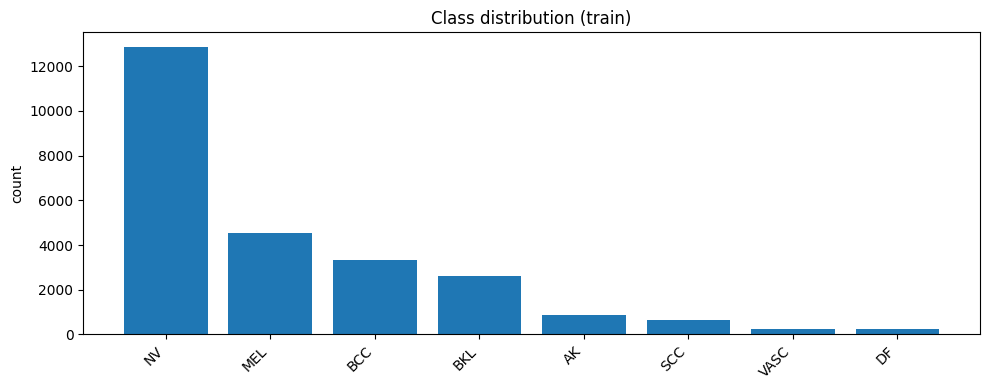

Imbalance ratio max/min: 53.87029288702929


In [6]:
counts = train[CLASS_COLS].sum(axis=0).sort_values(ascending=False)
perc = (counts / counts.sum() * 100).round(2)

dist = pd.DataFrame({"count": counts.astype(int), "pct": perc})
print(dist.to_string())

plt.figure(figsize=(10,4))
plt.bar(dist.index.astype(str), dist["count"].values)
plt.title("Class distribution (train)")
plt.xticks(rotation=45, ha="right")
plt.ylabel("count")
plt.tight_layout()
plt.show()

print("Imbalance ratio max/min:", float(dist["count"].max() / max(1, dist["count"].min())))

Metadata columns: ['age_approx', 'anatom_site_general', 'lesion_id', 'sex']


/var/folders/zw/6r3b0qhx56bbvd65b176cm1r0000gn/T/ipykernel_38312/1252155359.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_miss.set_xticklabels(x, rotation=25, ha="right")
/var/folders/zw/6r3b0qhx56bbvd65b176cm1r0000gn/T/ipykernel_38312/1252155359.py:85: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=rotate, ha="right")
/var/folders/zw/6r3b0qhx56bbvd65b176cm1r0000gn/T/ipykernel_38312/1252155359.py:85: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=rotate, ha="right")


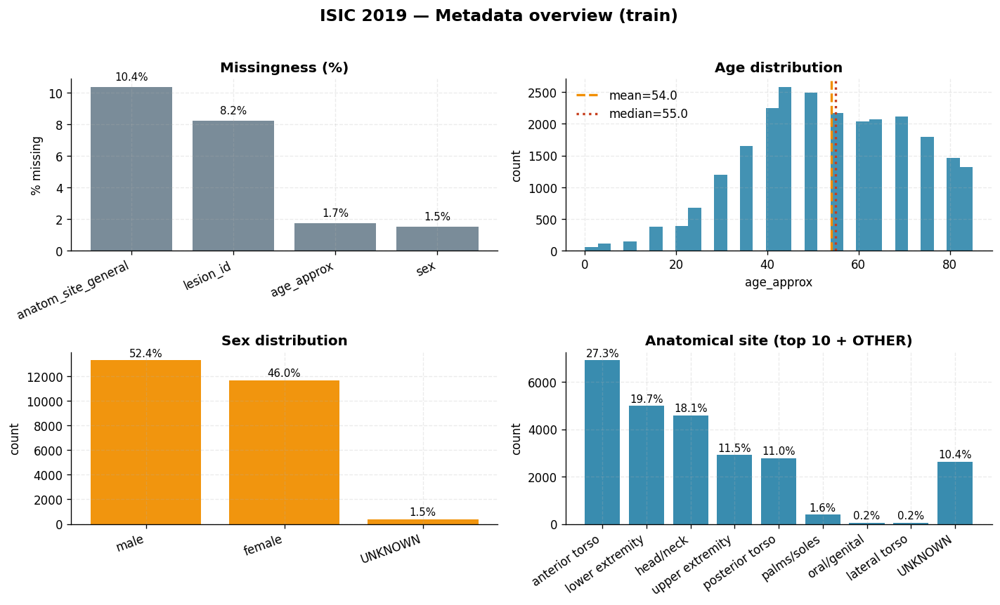

In [7]:
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10
})

C_MAIN   = "#2E86AB"   
C_ACCENT = "#F18F01"   
C_SOFT   = "#7A8C99"   
C_BAD    = "#C73E1D"  

NON_META = set(["image", "label_idx", "label_name"])
NON_META.update(CLASS_COLS)
NON_META.add("UNK")

meta_cols = [c for c in train.columns if c not in NON_META]
print("Metadata columns:", meta_cols)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
ax_miss, ax_age, ax_sex, ax_site = axes.ravel()

if len(meta_cols) > 0:
    miss = train[meta_cols].isna().mean().sort_values(ascending=False) * 100
    x = miss.index.astype(str).tolist()
    y = miss.values

    bars = ax_miss.bar(x, y, color=C_SOFT)
    ax_miss.set_title("Missingness (%)")
    ax_miss.set_ylabel("% missing")
    ax_miss.set_xticklabels(x, rotation=25, ha="right")

    for b, v in zip(bars, y):
        if v > 0:
            ax_miss.text(b.get_x() + b.get_width()/2, v + 0.3, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
else:
    ax_miss.set_title("Missingness (%)")
    ax_miss.text(0.5, 0.5, "No metadata columns", ha="center", va="center")
    ax_miss.axis("off")

if "age_approx" in train.columns:
    age = train["age_approx"].dropna().values
    ax_age.hist(age, bins=30, color=C_MAIN, alpha=0.9)
    ax_age.set_title("Age distribution")
    ax_age.set_xlabel("age_approx")
    ax_age.set_ylabel("count")

    if len(age) > 0:
        mean_age = float(np.mean(age))
        med_age  = float(np.median(age))
        ax_age.axvline(mean_age, color=C_ACCENT, linestyle="--", linewidth=2, label=f"mean={mean_age:.1f}")
        ax_age.axvline(med_age,  color=C_BAD,    linestyle=":",  linewidth=2, label=f"median={med_age:.1f}")
        ax_age.legend(frameon=False)
else:
    ax_age.set_title("Age distribution")
    ax_age.text(0.5, 0.5, "age_approx not found", ha="center", va="center")
    ax_age.axis("off")

def bar_pct(ax, series, title, color=C_MAIN, topk=None, rotate=30, force_order_end=("OTHER","UNKNOWN")):
    s = series.astype("string").fillna("UNKNOWN")

    if topk is not None:
        vc = s.value_counts()
        top = vc.head(topk)
        s = s.where(s.isin(top.index), other="OTHER")
    vc = s.value_counts()

    order = [x for x in vc.index.tolist() if x not in force_order_end]
    for k in force_order_end:
        if k in vc.index:
            order.append(k)

    vc = vc.reindex(order)
    labels = vc.index.astype(str).tolist()
    counts = vc.values
    total = counts.sum()

    bars = ax.bar(labels, counts, color=color, alpha=0.95)
    ax.set_title(title)
    ax.set_ylabel("count")
    ax.set_xticklabels(labels, rotation=rotate, ha="right")

    for b, c in zip(bars, counts):
        pct = 100 * c / total if total > 0 else 0
        ax.text(b.get_x() + b.get_width()/2, c + max(1, 0.01*counts.max()), f"{pct:.1f}%", ha="center", va="bottom", fontsize=9)

if "sex" in train.columns:
    bar_pct(ax_sex, train["sex"], "Sex distribution", color=C_ACCENT, topk=None, rotate=20, force_order_end=("UNKNOWN",))
else:
    ax_sex.set_title("Sex distribution")
    ax_sex.text(0.5, 0.5, "sex not found", ha="center", va="center")
    ax_sex.axis("off")

if "anatom_site_general" in train.columns:
    bar_pct(ax_site, train["anatom_site_general"], "Anatomical site (top 10 + OTHER)", color=C_MAIN, topk=10, rotate=35)
else:
    ax_site.set_title("Anatomical site")
    ax_site.text(0.5, 0.5, "anatom_site_general not found", ha="center", va="center")
    ax_site.axis("off")

fig.suptitle("ISIC 2019 — Metadata overview (train)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

/var/folders/zw/6r3b0qhx56bbvd65b176cm1r0000gn/T/ipykernel_38312/2234688394.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(


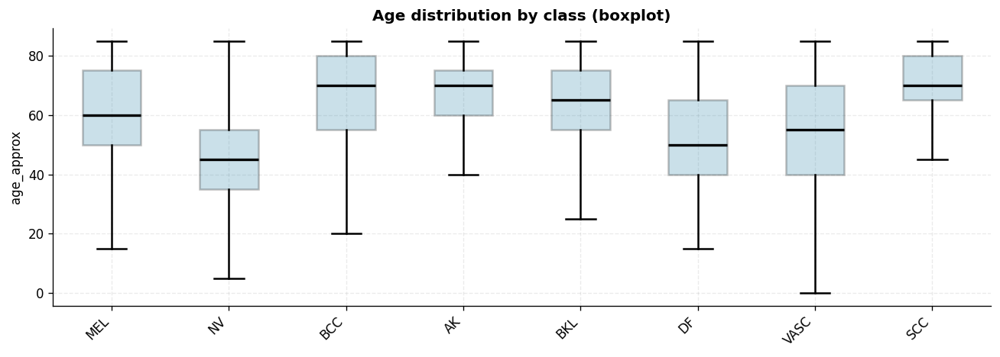

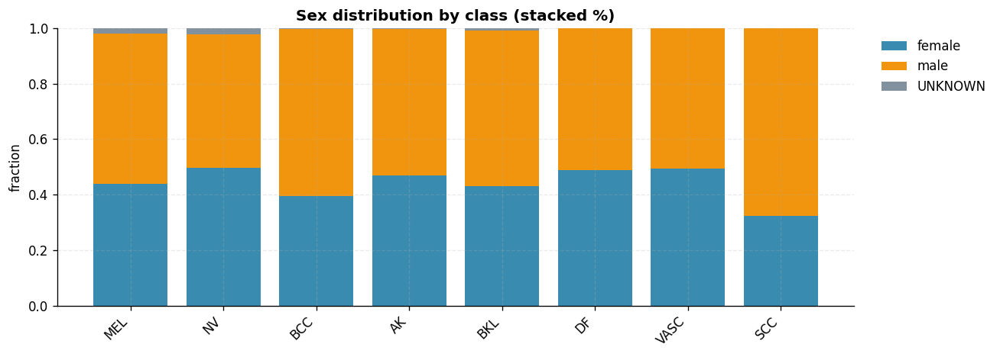

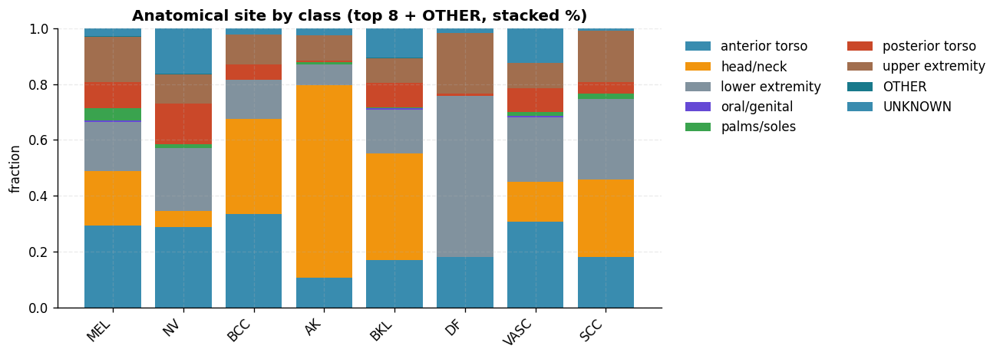

In [8]:
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10
})

C_MAIN   = "#2E86AB"
C_ACCENT = "#F18F01"
C_SOFT   = "#7A8C99"

class_order = [idx_to_class[i] for i in range(len(CLASS_COLS))]
tmp = train.copy()

if "age_approx" in tmp.columns:
    data, labels = [], []
    for i in range(len(CLASS_COLS)):
        vals = tmp.loc[tmp["label_idx"] == i, "age_approx"].dropna().values
        if len(vals) > 0:
            data.append(vals)
            labels.append(idx_to_class[i])

    if len(data) > 0:
        plt.figure(figsize=(11,4))
        bp = plt.boxplot(
            data,
            labels=labels,
            showfliers=False,
            patch_artist=True,
            medianprops=dict(color="black", linewidth=2),
            boxprops=dict(linewidth=1.5),
            whiskerprops=dict(linewidth=1.5),
            capprops=dict(linewidth=1.5)
        )
        for box in bp["boxes"]:
            box.set_facecolor(C_MAIN)
            box.set_alpha(0.25)

        plt.title("Age distribution by class (boxplot)")
        plt.ylabel("age_approx")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()


def stacked_pct_bar(ct, title, ncol_legend=1):
    ct_pct = ct.div(ct.sum(axis=1), axis=0).fillna(0.0)

    plt.figure(figsize=(11,4))
    x = np.arange(len(ct_pct))
    bottom = np.zeros(len(ct_pct))

    palette = [C_MAIN, C_ACCENT, C_SOFT, "#5D3FD3", "#2F9E44", "#C73E1D", "#9C6644", "#0B7285"]

    for j, col in enumerate(ct_pct.columns):
        vals = ct_pct[col].values
        plt.bar(x, vals, bottom=bottom, label=str(col), color=palette[j % len(palette)], alpha=0.95)
        bottom += vals

    plt.title(title)
    plt.ylabel("fraction")
    plt.xticks(x, ct_pct.index, rotation=45, ha="right")
    plt.ylim(0, 1.0)
    plt.legend(frameon=False, ncol=ncol_legend, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


if "sex" in tmp.columns:
    tmp["sex"] = tmp["sex"].astype("string").fillna("UNKNOWN")

    ct = pd.crosstab(tmp["label_name"], tmp["sex"])

    ordered_idx = [c for c in class_order if c in ct.index]
    ct = ct.loc[ordered_idx]

    cols = ct.columns.tolist()
    cols = [c for c in cols if c != "UNKNOWN"] + (["UNKNOWN"] if "UNKNOWN" in cols else [])
    ct = ct[cols]

    stacked_pct_bar(ct, "Sex distribution by class (stacked %)", ncol_legend=1)


if "anatom_site_general" in tmp.columns:
    tmp["anatom_site_general"] = tmp["anatom_site_general"].astype("string").fillna("UNKNOWN")

    top_sites = tmp["anatom_site_general"].value_counts().head(8).index.tolist()
    tmp["site_top"] = tmp["anatom_site_general"].where(tmp["anatom_site_general"].isin(top_sites), other="OTHER")

    ct = pd.crosstab(tmp["label_name"], tmp["site_top"])

    ordered_idx = [c for c in class_order if c in ct.index]
    ct = ct.loc[ordered_idx]

    cols = ct.columns.tolist()
    core = [c for c in cols if c not in ["OTHER", "UNKNOWN"]]
    tail = []
    if "OTHER" in cols: tail.append("OTHER")
    if "UNKNOWN" in cols: tail.append("UNKNOWN")
    ct = ct[core + tail]

    stacked_pct_bar(ct, "Anatomical site by class (top 8 + OTHER, stacked %)", ncol_legend=2)

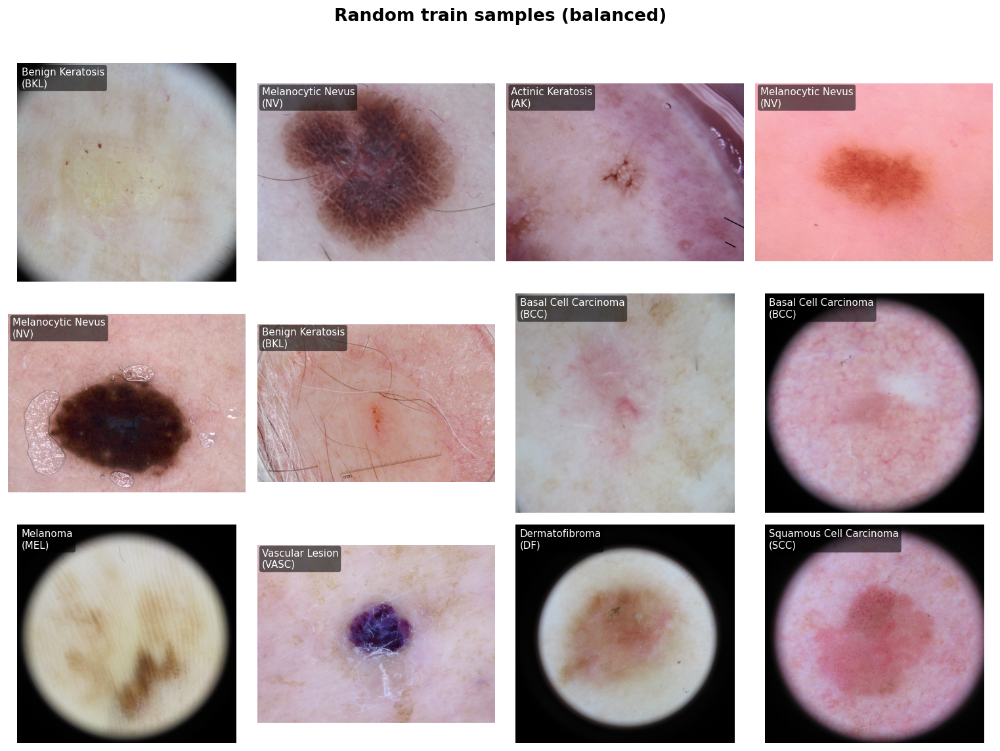

In [9]:
CLASS_LONG = {
    "MEL": "Melanoma",
    "NV":  "Melanocytic Nevus",
    "BCC": "Basal Cell Carcinoma",
    "AK":  "Actinic Keratosis",
    "BKL": "Benign Keratosis",
    "DF":  "Dermatofibroma",
    "VASC":"Vascular Lesion",
    "SCC": "Squamous Cell Carcinoma",
    "UNK": "Unknown"
}

def show_grid_demo(df, img_dir: Path, n=12, title="Samples", cols=4, balanced=True, seed=42):
    rng = np.random.RandomState(seed)

    if balanced and "label_name" in df.columns:
        classes = sorted(df["label_name"].unique())
        per_class = max(1, n // max(1, len(classes)))
        picks = []
        for c in classes:
            sub = df[df["label_name"] == c]
            if len(sub) == 0:
                continue
            k = min(per_class, len(sub))
            picks.append(sub.sample(k, random_state=int(rng.randint(0, 10_000))))
        picks = pd.concat(picks, ignore_index=True) if len(picks) else df.sample(n, random_state=seed)
        if len(picks) < n:
            extra = df.drop(picks.index, errors="ignore").sample(min(n - len(picks), len(df)), random_state=seed)
            picks = pd.concat([picks, extra], ignore_index=True)
        picks = picks.sample(n=min(n, len(picks)), random_state=seed).reset_index(drop=True)
    else:
        picks = df.sample(min(n, len(df)), random_state=seed).reset_index(drop=True)

    rows = int(np.ceil(len(picks) / cols))
    fig = plt.figure(figsize=(3.2*cols, 3.1*rows))
    fig.suptitle(title, fontsize=16, fontweight="bold", y=1.02)

    for i in range(len(picks)):
        row = picks.iloc[i]
        img_id = row["image"]
        label = row.get("label_name", "NA")
        long = CLASS_LONG.get(label, label)

        p = resolve_image_path(img_dir, img_id)
        img = Image.open(p).convert("RGB") if p else Image.new("RGB", (224,224))

        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(img)
        ax.axis("off")

        badge_text = f"{long}\n({label})"
        ax.text(
            0.02, 0.98, badge_text,
            transform=ax.transAxes,
            va="top", ha="left",
            fontsize=9, color="white",
            bbox=dict(boxstyle="round,pad=0.25", facecolor="black", alpha=0.55, edgecolor="none")
        )

    plt.tight_layout()
    plt.show()
    
show_grid_demo(train, TRAIN_IMG_DIR, n=12, title="Random train samples (balanced)", cols=4, balanced=True)

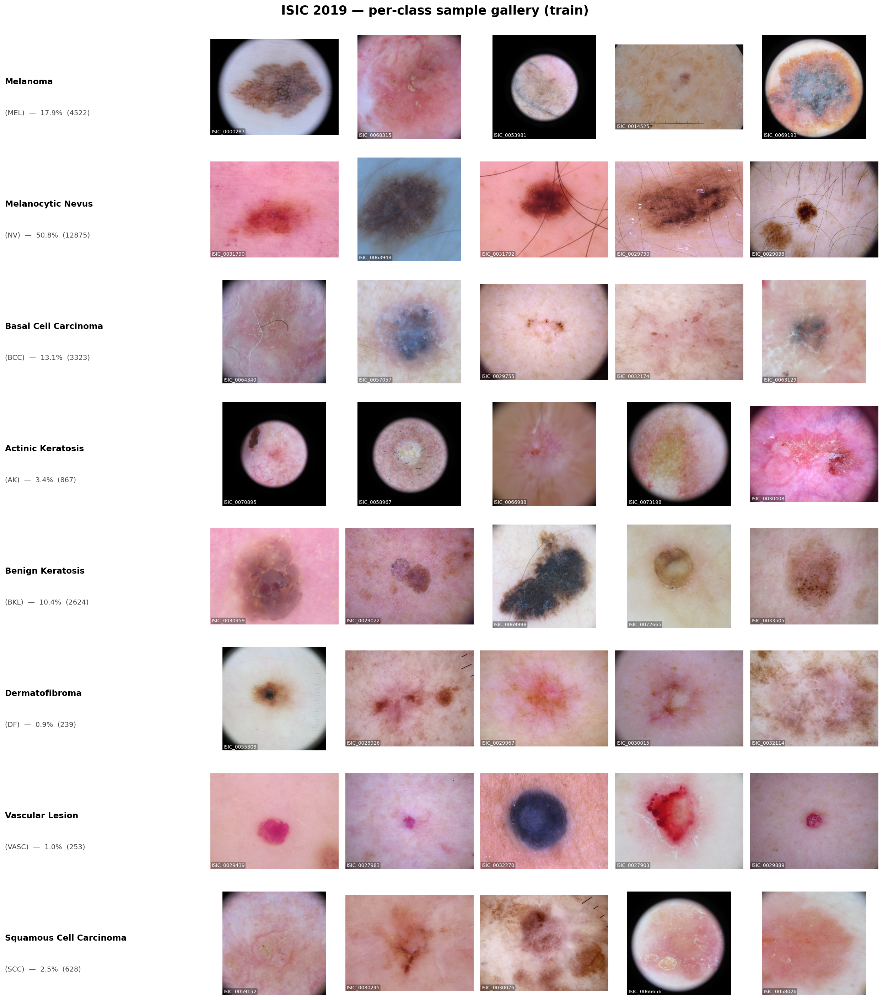

In [10]:
CLASS_LONG = {
    "MEL": "Melanoma",
    "NV":  "Melanocytic Nevus",
    "BCC": "Basal Cell Carcinoma",
    "AK":  "Actinic Keratosis",
    "BKL": "Benign Keratosis",
    "DF":  "Dermatofibroma",
    "VASC":"Vascular Lesion",
    "SCC": "Squamous Cell Carcinoma",
    "UNK": "Unknown"
}

def show_gallery_by_class_pro(df, img_dir: Path, n_per_class=5, seed=42, title="ISIC 2019 — per-class sample gallery (train)"):
    rng = np.random.RandomState(seed)
    classes = list(range(len(CLASS_COLS)))
    rows = len(classes)
    cols = n_per_class

    class_counts = df["label_idx"].value_counts().to_dict()
    total = len(df)

    fig = plt.figure(figsize=(3.0*(cols+1), 2.55*rows), dpi=140)
    gs = gridspec.GridSpec(
        rows, cols + 1,
        figure=fig,
        width_ratios=[1.55] + [1]*cols,
        wspace=0.05,
        hspace=0.18
    )

    fig.suptitle(title, fontsize=18, fontweight="bold", y=0.995)

    for r, cidx in enumerate(classes):
        ax_label = fig.add_subplot(gs[r, 0])
        ax_label.axis("off")

        short = idx_to_class[cidx]
        long = CLASS_LONG.get(short, short)

        cnt = int(class_counts.get(cidx, 0))
        pct = (100 * cnt / total) if total > 0 else 0.0

        ax_label.text(
            0.0, 0.55,
            f"{long}",
            va="center", ha="left",
            fontsize=12, fontweight="bold"
        )
        ax_label.text(
            0.0, 0.25,
            f"({short})  —  {pct:.1f}%  ({cnt})",
            va="center", ha="left",
            fontsize=10, color="#444444"
        )

        sub = df[df["label_idx"] == cidx]
        if len(sub) == 0:
            for j in range(cols):
                ax = fig.add_subplot(gs[r, j+1]); ax.axis("off")
            continue

        picks = sub.sample(min(cols, len(sub)), random_state=int(rng.randint(0, 10_000))).reset_index(drop=True)

        for j in range(cols):
            ax = fig.add_subplot(gs[r, j+1])
            ax.axis("off")
            if j >= len(picks):
                continue

            img_id = picks.loc[j, "image"]
            p = resolve_image_path(img_dir, img_id)
            img = Image.open(p).convert("RGB") if p else Image.new("RGB", (224,224))

            ax.imshow(img)

            ax.text(
                0.01, 0.01, img_id[:12],
                transform=ax.transAxes,
                ha="left", va="bottom",
                fontsize=7, color="white",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="black", alpha=0.35, edgecolor="none")
            )

    fig.subplots_adjust(top=0.965, bottom=0.02, left=0.02, right=0.995)
    plt.show()

show_gallery_by_class_pro(train, TRAIN_IMG_DIR, n_per_class=5)

In [11]:
assert "lesion_id" in train.columns, "lesion_id not found in train metadata."

n_total = len(train)
n_missing = int(train["lesion_id"].isna().sum())
missing_rate = n_missing / n_total

non = train.loc[train["lesion_id"].notna(), ["image", "lesion_id", "label_name"]].copy()

grp_sizes = non.groupby("lesion_id").size().sort_values(ascending=False)

n_lesions = int(grp_sizes.shape[0])
max_size = int(grp_sizes.iloc[0])
n_multi = int((grp_sizes > 1).sum())
pct_multi_lesions = n_multi / n_lesions if n_lesions > 0 else 0.0

imgs_in_multi = int(grp_sizes[grp_sizes > 1].sum())
pct_imgs_in_multi = imgs_in_multi / len(non) if len(non) > 0 else 0.0

print("=== Lesion-level (lesion_id) summary ===")
print(f"Total train images: {n_total}")
print(f"Missing lesion_id: {n_missing} ({missing_rate:.1%})")
print(f"Non-missing images: {len(non)}")
print(f"Distinct lesions (non-missing): {n_lesions}")
print(f"Max images per lesion: {max_size}")
print(f"Lesions with >1 image: {n_multi} ({pct_multi_lesions:.1%} of lesions)")
print(f"Images belonging to multi-image lesions: {imgs_in_multi} ({pct_imgs_in_multi:.1%} of non-missing images)")

print("\nTop 10 lesion_id by number of images:")
print(grp_sizes.head(10).to_string())

=== Lesion-level (lesion_id) summary ===
Total train images: 25331
Missing lesion_id: 2084 (8.2%)
Non-missing images: 23247
Distinct lesions (non-missing): 11847
Max images per lesion: 31
Lesions with >1 image: 5059 (42.7% of lesions)
Images belonging to multi-image lesions: 16459 (70.8% of non-missing images)

Top 10 lesion_id by number of images:
lesion_id
BCN_0001728    31
BCN_0003369    27
BCN_0001321    26
BCN_0003196    24
BCN_0001954    21
BCN_0003907    20
BCN_0000861    20
BCN_0005108    20
BCN_0005210    20
BCN_0001755    20


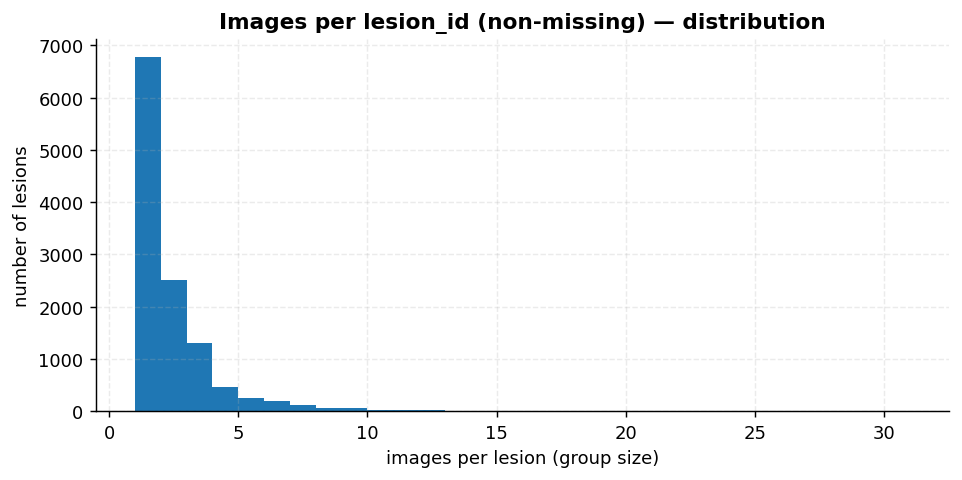

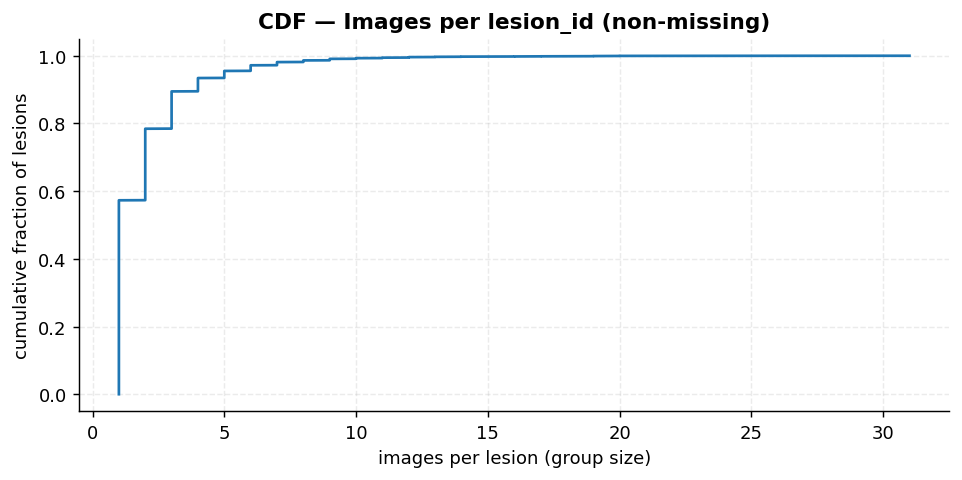

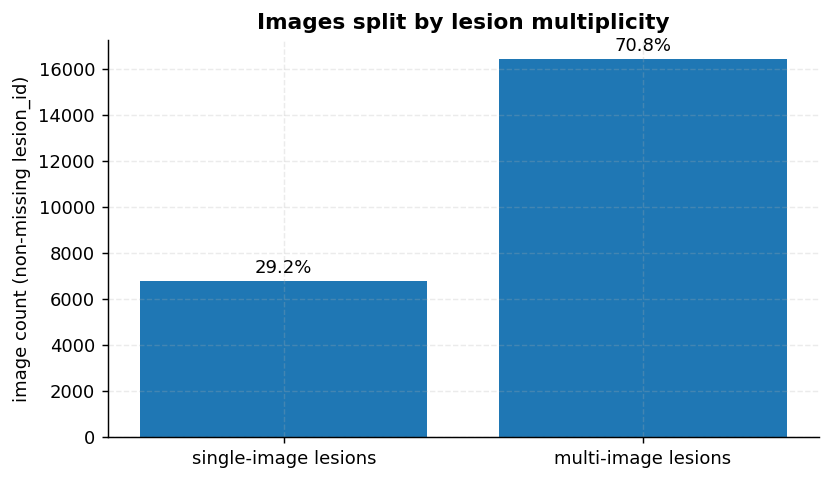

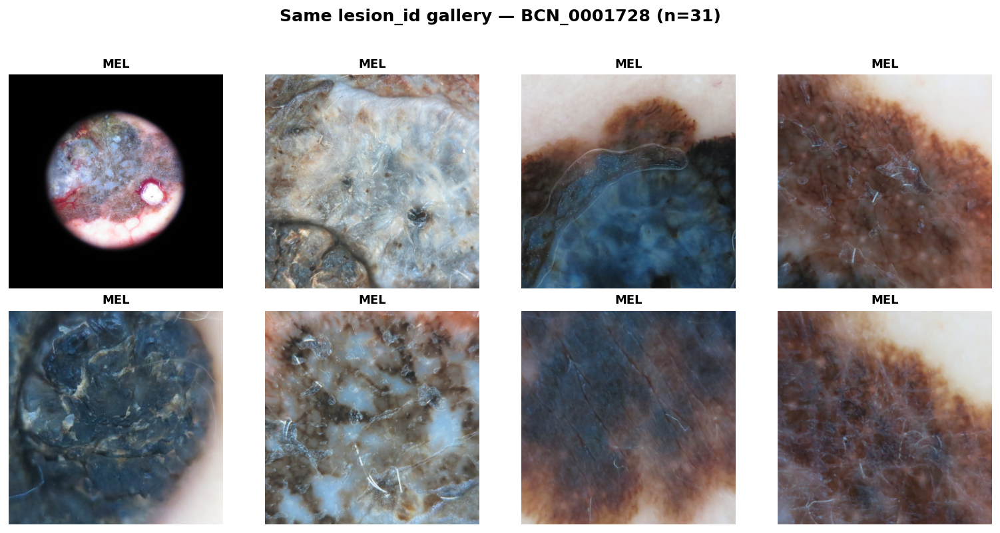

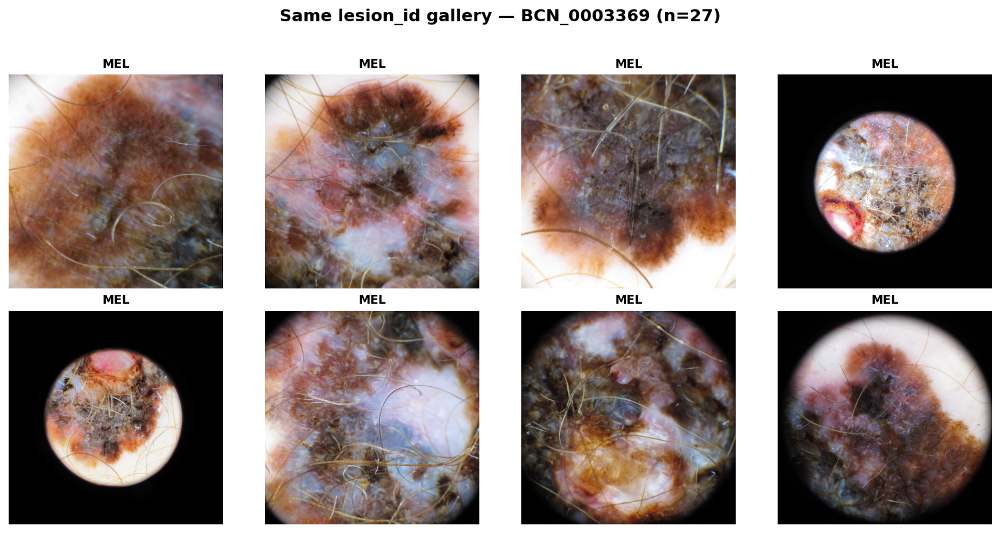

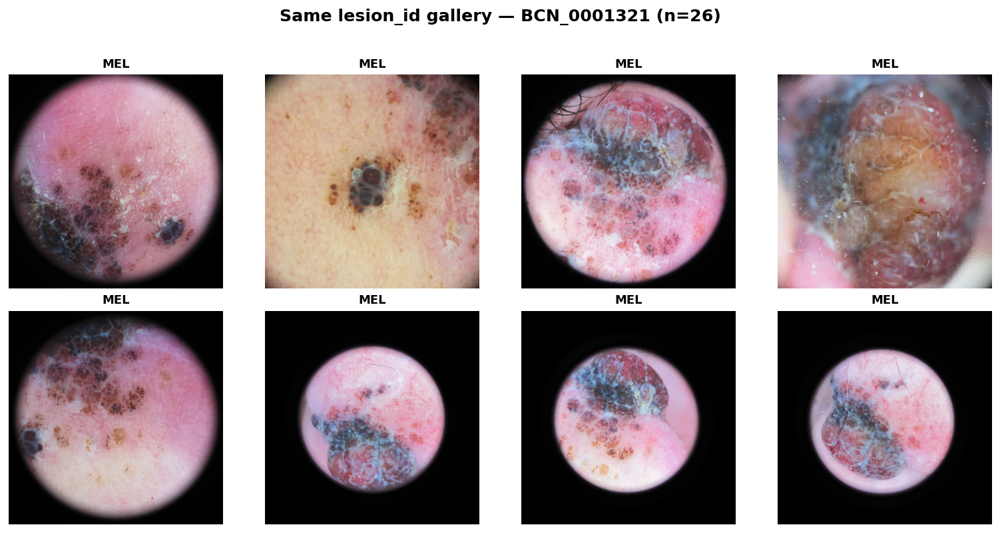

Note: These galleries illustrate why we must use group-aware splitting by lesion_id (to avoid leakage).


In [12]:
plt.figure(figsize=(7.5, 3.8), dpi=130)
plt.hist(grp_sizes.values, bins=30)
plt.title("Images per lesion_id (non-missing) — distribution")
plt.xlabel("images per lesion (group size)")
plt.ylabel("number of lesions")
plt.tight_layout()
plt.show()

sorted_sizes = np.sort(grp_sizes.values)
cdf = np.arange(1, len(sorted_sizes) + 1) / len(sorted_sizes)

plt.figure(figsize=(7.5, 3.8), dpi=130)
plt.plot(sorted_sizes, cdf)
plt.title("CDF — Images per lesion_id (non-missing)")
plt.xlabel("images per lesion (group size)")
plt.ylabel("cumulative fraction of lesions")
plt.grid(True, alpha=0.25, linestyle="--")
plt.tight_layout()
plt.show()

share = pd.Series({
    "single-image lesions": len(non) - imgs_in_multi,
    "multi-image lesions": imgs_in_multi
})

plt.figure(figsize=(6.5, 3.8), dpi=130)
plt.bar(share.index.astype(str), share.values)
plt.title("Images split by lesion multiplicity")
plt.ylabel("image count (non-missing lesion_id)")
for i, v in enumerate(share.values):
    pct = 100 * v / share.values.sum()
    plt.text(i, v + 0.01*share.values.max(), f"{pct:.1f}%", ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()

def show_lesion_gallery(lesion_id, n=8):
    sub = non[non["lesion_id"] == lesion_id].copy()
    n = min(n, len(sub))
    picks = sub.sample(n, random_state=42).reset_index(drop=True)

    cols = 4
    rows = int(np.ceil(n / cols))

    plt.figure(figsize=(12, 3*rows), dpi=130)
    plt.suptitle(f"Same lesion_id gallery — {lesion_id} (n={len(sub)})", y=1.02, fontsize=14, fontweight="bold")

    for i in range(n):
        img_id = picks.loc[i, "image"]
        label = picks.loc[i, "label_name"]
        p = resolve_image_path(TRAIN_IMG_DIR, img_id)
        img = Image.open(p).convert("RGB") if p else Image.new("RGB",(224,224))

        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"{label}", fontsize=10)

    plt.tight_layout()
    plt.show()

top_lesions = grp_sizes.head(3).index.tolist()
for lid in top_lesions:
    show_lesion_gallery(lid, n=8)

print("Note: These galleries illustrate why we must use group-aware splitting by lesion_id (to avoid leakage).")

Computed quality metrics on: 1200 images


,brightness,contrast,sharpness,saturation
count,1200.00,1200.00,1200.00,1200.00
mean,145.58,36.29,73.76,63.09
std,29.25,20.99,158.46,31.91
min,39.26,7.07,2.53,6.01
25%,131.70,20.37,22.01,39.03
50%,149.92,30.13,36.38,56.59
75%,164.61,47.31,66.82,85.77
max,229.03,95.33,3567.80,175.60


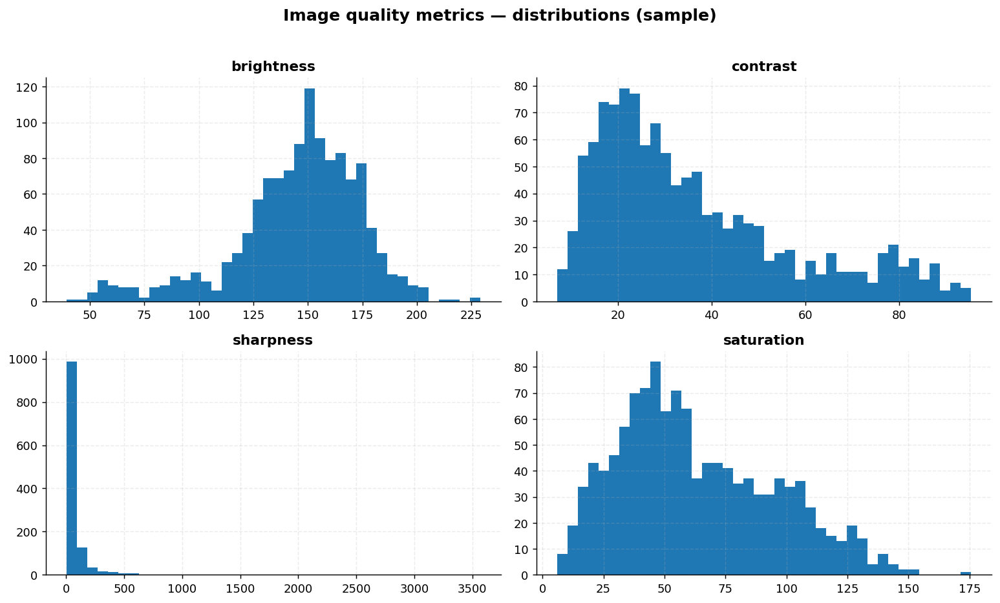

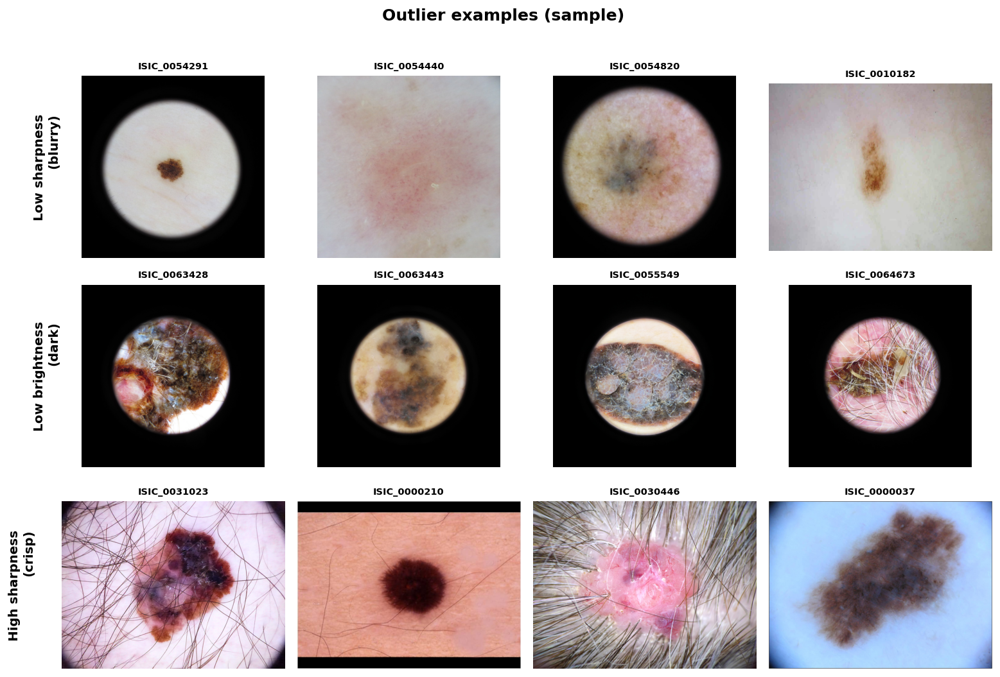

In [13]:
assert cv2 is not None, "opencv not installed. pip install opencv-python"

def load_bgr(img_id):
    p = resolve_image_path(TRAIN_IMG_DIR, img_id)
    if p is None:
        return None
    return cv2.imread(str(p))

def quality_metrics(bgr):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    bright = float(gray.mean())
    contrast = float(gray.std())
    sharp = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    sat = float(hsv[:,:,1].mean())
    return bright, contrast, sharp, sat

sample_n = 1200
sample_ids = train.sample(sample_n, random_state=42)["image"].tolist()

rows = []
for img_id in sample_ids:
    bgr = load_bgr(img_id)
    if bgr is None:
        continue
    bright, contrast, sharp, sat = quality_metrics(bgr)
    rows.append((img_id, bright, contrast, sharp, sat))

qdf = pd.DataFrame(rows, columns=["image","brightness","contrast","sharpness","saturation"])
print("Computed quality metrics on:", len(qdf), "images")
display(qdf.describe().round(2))

plt.figure(figsize=(12,7), dpi=130)

for i, col in enumerate(["brightness","contrast","sharpness","saturation"], 1):
    ax = plt.subplot(2,2,i)
    ax.hist(qdf[col], bins=40)
    ax.set_title(col, fontweight="bold")
    ax.grid(True, alpha=0.25, linestyle="--")

plt.suptitle("Image quality metrics — distributions (sample)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

def show_row(ids, row_idx, label):
    for j, img_id in enumerate(ids[:4], 1):
        p = resolve_image_path(TRAIN_IMG_DIR, img_id)
        img = Image.open(p).convert("RGB") if p else Image.new("RGB",(224,224))
        ax = plt.subplot(3,4,(row_idx-1)*4 + j)
        ax.imshow(img); ax.axis("off")
        ax.set_title(img_id[:12], fontsize=8)
    ax0 = plt.subplot(3,4,(row_idx-1)*4 + 1)
    ax0.text(-0.12, 0.5, label, transform=ax0.transAxes, rotation=90,
             va="center", ha="right", fontsize=11, fontweight="bold")

low_sharp = qdf.nsmallest(4, "sharpness")["image"].tolist()
low_bright = qdf.nsmallest(4, "brightness")["image"].tolist()
hi_sharp = qdf.nlargest(4, "sharpness")["image"].tolist()

plt.figure(figsize=(12,8), dpi=130)
show_row(low_sharp, 1, "Low sharpness\n(blurry)")
show_row(low_bright, 2, "Low brightness\n(dark)")
show_row(hi_sharp, 3, "High sharpness\n(crisp)")
plt.suptitle("Outlier examples (sample)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## Split-Aware

In [15]:
df = train.copy()

df["lesion_group"] = df["lesion_id"].astype("string")
df["lesion_group"] = df["lesion_group"].fillna("IMG_" + df["image"].astype("string"))

X = df[["image"]].values  # dummy
y = df["label_idx"].values
groups = df["lesion_group"].values

SEED = 42
N_SPLITS = 5
VAL_FOLD = 0  

sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
splits = list(sgkf.split(X, y, groups=groups))

train_idx, val_idx = splits[VAL_FOLD]
train_split = df.iloc[train_idx].reset_index(drop=True)
val_split   = df.iloc[val_idx].reset_index(drop=True)

print("train/val sizes:", len(train_split), len(val_split))

train_groups = set(train_split["lesion_group"])
val_groups = set(val_split["lesion_group"])
overlap = train_groups.intersection(val_groups)
print("Group overlap:", len(overlap))
if len(overlap) > 0:
    print("Example overlapping groups:", list(overlap)[:10])

def class_dist(df_part, name):
    counts = df_part["label_idx"].value_counts().sort_index()
    counts = counts.reindex(range(len(CLASS_COLS)), fill_value=0)
    pct = (counts / counts.sum()).values
    out = pd.DataFrame({
        "class": [idx_to_class[i] for i in range(len(CLASS_COLS))],
        f"{name}_count": counts.values,
        f"{name}_pct": np.round(pct, 4),
    })
    return out

dist_tr = class_dist(train_split, "train")
dist_va = class_dist(val_split, "val")

dist = dist_tr.merge(dist_va, on="class")
dist["abs_pct_diff"] = (dist["train_pct"] - dist["val_pct"]).abs()
print("\nClass balance train vs val:")
display(dist.sort_values("abs_pct_diff", ascending=False))

print("\nMean abs pct diff:", dist["abs_pct_diff"].mean())

def lesion_stats(df_part, name):
    non = df_part[df_part["lesion_id"].notna()].copy()
    if len(non) == 0:
        return pd.Series({"split": name, "non_missing_imgs": 0, "n_lesions": 0, "pct_multi_lesions": np.nan})
    grp = non.groupby("lesion_id").size()
    n_lesions = int(grp.shape[0])
    pct_multi = float((grp > 1).mean()) if n_lesions > 0 else np.nan
    return pd.Series({
        "split": name,
        "non_missing_imgs": int(len(non)),
        "n_lesions": n_lesions,
        "max_imgs_per_lesion": int(grp.max()),
        "pct_multi_lesions": pct_multi,
    })

stats = pd.DataFrame([lesion_stats(train_split, "train"), lesion_stats(val_split, "val")])
display(stats)

train_split.head(), val_split.head()

train/val sizes: 20327 5004
Group overlap: 0

Class balance train vs val:


,class,train_count,train_pct,val_count,val_pct,abs_pct_diff
2,BCC,2586,0.1272,737,0.1473,0.0201
0,MEL,3679,0.1810,843,0.1685,0.0125
1,NV,10376,0.5105,2499,0.4994,0.0111
6,VASC,177,0.0087,76,0.0152,0.0065
3,AK,713,0.0351,154,0.0308,0.0043
7,SCC,513,0.0252,115,0.0230,0.0022
4,BKL,2097,0.1032,527,0.1053,0.0021
5,DF,186,0.0092,53,0.0106,0.0014



Mean abs pct diff: 0.007524999999999988


,split,non_missing_imgs,n_lesions,max_imgs_per_lesion,pct_multi_lesions
0,train,18661,9478,31,0.428993
1,val,4586,2369,24,0.419164


(          image  MEL   NV  BCC   AK  BKL   DF  VASC  SCC  UNK  label_idx  \
 0  ISIC_0000000  0.0  1.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          1   
 1  ISIC_0000002  1.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          0   
 2  ISIC_0000003  0.0  1.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          1   
 3  ISIC_0000004  1.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          0   
 4  ISIC_0000006  0.0  1.0  0.0  0.0  0.0  0.0   0.0  0.0  0.0          1   
 
   label_name  age_approx anatom_site_general lesion_id     sex  \
 0         NV        55.0      anterior torso       NaN  female   
 1        MEL        60.0     upper extremity       NaN  female   
 2         NV        30.0     upper extremity       NaN    male   
 3        MEL        80.0     posterior torso       NaN    male   
 4         NV        25.0     posterior torso       NaN  female   
 
        lesion_group  
 0  IMG_ISIC_0000000  
 1  IMG_ISIC_0000002  
 2  IMG_ISIC_0000003  
 3  IMG_ISIC_0000004  
 4  IMG_ISIC_0000

,split,n,missing,missing_rate
0,train,20327,1666,0.081960
1,val,5004,418,0.083533


,class,train_rate,val_rate
5,NV,0.120085,0.121248
2,BKL,0.073915,0.081594
4,MEL,0.072030,0.085409


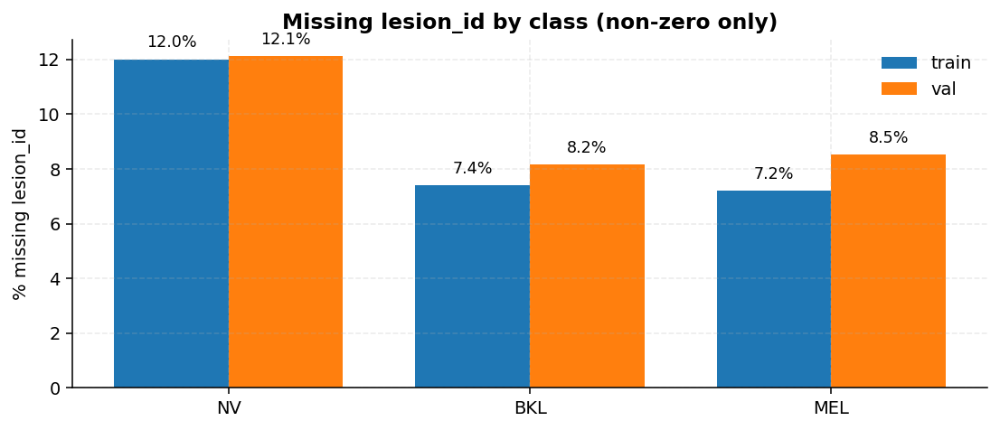

In [16]:
def missing_summary(df_part, name):
    n = len(df_part)
    miss = int(df_part["lesion_id"].isna().sum())
    return pd.Series({"split": name, "n": n, "missing": miss, "missing_rate": miss/n})

summary = pd.DataFrame([missing_summary(train_split, "train"),
                        missing_summary(val_split, "val")])
display(summary)

def missing_by_class(df_part, name):
    tmp = df_part.copy()
    tmp["missing"] = tmp["lesion_id"].isna().astype(int)
    g = tmp.groupby("label_idx")["missing"].agg(n="count", missing="sum").reset_index()
    g["class"] = g["label_idx"].map(lambda i: idx_to_class[int(i)])
    g[f"{name}_rate"] = g["missing"] / g["n"]
    return g[["class", f"{name}_rate"]]

mb = missing_by_class(train_split, "train").merge(missing_by_class(val_split, "val"), on="class", how="outer").fillna(0)
mb = mb[(mb["train_rate"] > 0) | (mb["val_rate"] > 0)].sort_values("train_rate", ascending=False)
display(mb)

x = np.arange(len(mb))
w = 0.38
plt.figure(figsize=(8,3.5), dpi=140)
b1 = plt.bar(x - w/2, mb["train_rate"]*100, width=w, label="train")
b2 = plt.bar(x + w/2, mb["val_rate"]*100, width=w, label="val")
plt.xticks(x, mb["class"], rotation=0)
plt.ylabel("% missing lesion_id")
plt.title("Missing lesion_id by class (non-zero only)", fontweight="bold")
plt.grid(True, alpha=0.25, linestyle="--")
plt.legend(frameon=False)
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x()+bar.get_width()/2, h+0.3, f"{h:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()